In [ ]:
import pandas as pd

df = pd.read_csv('/content/sahil.csv')

print("Original shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df.columns = df.columns.str.strip()
df = df.drop_duplicates()

for col in ['Order Date', 'Ship Date']:
    df[col] = pd.to_datetime(df[col], errors='coerce')

for col in ['Sales', 'Quantity', 'Discount', 'Profit']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("\nDate errors:", df[['Order Date', 'Ship Date']].isnull().sum().sum())
print("Final shape:", df.shape)
print("\nData types:\n", df.dtypes)

df.to_csv('/content/superstore_cleaned.csv', index=False)
print("\nCleaned dataset saved successfully.")

Original shape: (100000, 25)

Missing values:
 Customer ID          0
Customer Name        0
Last Name            0
Date of Birth        0
Sales                0
Year                 0
Outlet Type          0
City Type            0
Category of Goods    0
Region               0
Country              0
Segment              0
Sales Date           0
Order ID             0
Order Date           0
Ship Date            0
Ship Mode            0
State                0
Postal Code          0
Product ID           0
Sub-Category         0
Product Name         0
Quantity             0
Discount             0
Profit               0
dtype: int64

Duplicate rows: 0


/tmp/ipykernel_2250/1341584666.py:13: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df[col] = pd.to_datetime(df[col], errors='coerce')
/tmp/ipykernel_2250/1341584666.py:13: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df[col] = pd.to_datetime(df[col], errors='coerce')



Date errors: 0
Final shape: (100000, 25)

Data types:
 Customer ID                  object
Customer Name                object
Last Name                    object
Date of Birth                object
Sales                       float64
Year                          int64
Outlet Type                  object
City Type                    object
Category of Goods            object
Region                       object
Country                      object
Segment                      object
Sales Date                   object
Order ID                     object
Order Date           datetime64[ns]
Ship Date            datetime64[ns]
Ship Mode                    object
State                        object
Postal Code                   int64
Product ID                   object
Sub-Category                 object
Product Name                 object
Quantity                      int64
Discount                    float64
Profit                      float64
dtype: object

Cleaned dataset saved success

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/sahil.csv')

print(df.shape)
display(df.head())


(100000, 25)


,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Ship Date,Ship Mode,State,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit
0,CUST000001,Curtis,Krause,29-11-1973,3344.69,2023,Large,Tier 1,Fast Food,East,...,18-04-2020,Same Day,West Bengal,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24
1,CUST000002,Jeremy,Foster,30-08-1987,37094.41,2022,Medium,Tier 2,Fast Food,East,...,11-01-2021,Standard Class,Punjab,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34
2,CUST000003,Ariel,Mccann,15-12-1980,35501.08,2023,Large,Village,Electric Appliances,South,...,16-08-2020,Second Class,Gujarat,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21
3,CUST000004,Colleen,Maynard,23-05-1989,8969.33,2021,Medium,Village,Dairy Products,East,...,16-10-2021,First Class,West Bengal,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66
4,CUST000005,Gina,Holden,31-12-1957,35530.44,2021,Small,Village,Sessional Fruits & Vegetables,West,...,25-01-2019,Standard Class,Delhi,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93


In [ ]:

print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
display(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Customer ID        100000 non-null  object 
 1   Customer Name      100000 non-null  object 
 2   Last Name          100000 non-null  object 
 3   Date of Birth      100000 non-null  object 
 4   Sales              100000 non-null  float64
 5   Year               100000 non-null  int64  
 6   Outlet Type        100000 non-null  object 
 7   City Type          100000 non-null  object 
 8   Category of Goods  100000 non-null  object 
 9   Region             100000 non-null  object 
 10  Country            100000 non-null  object 
 11  Segment            100000 non-null  object 
 12  Sales Date         100000 non-null  object 
 13  Order ID           100000 non-null  object 
 14  Order Date         100000 non-null  object 
 15  Ship Date          100000 non-null  object 
 16  Shi

,Sales,Year,Postal Code,Quantity,Discount,Profit
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,25084.410142,2020.999910,388985.180000,5.493760,0.251320,3755.305114
std,14403.187686,1.413757,184192.704685,2.876102,0.144324,2639.852035
min,100.570000,2019.000000,110001.000000,1.000000,0.000000,6.520000
25%,12618.030000,2020.000000,226001.000000,3.000000,0.130000,1651.105000
50%,25134.695000,2021.000000,380001.000000,5.000000,0.250000,3317.450000
75%,37575.850000,2022.000000,560001.000000,8.000000,0.380000,5363.845000
max,49999.890000,2023.000000,700001.000000,10.000000,0.500000,14563.670000


In [ ]:

df.columns = df.columns.str.strip()
df = df.drop_duplicates()

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

for col in df.columns:
    if 'date' in col.lower():
        df[col] = pd.to_datetime(df[col], errors='coerce')

print("Shape after cleaning:", df.shape)
print("Missing values:\n", df.isnull().sum())


/tmp/ipykernel_2250/347412279.py:9: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df[col] = pd.to_datetime(df[col], errors='coerce')
/tmp/ipykernel_2250/347412279.py:9: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df[col] = pd.to_datetime(df[col], errors='coerce')


Shape after cleaning: (100000, 25)
Missing values:
 Customer ID              0
Customer Name            0
Last Name                0
Date of Birth            0
Sales                    0
Year                     0
Outlet Type              0
City Type                0
Category of Goods        0
Region                   0
Country                  0
Segment                  0
Sales Date           60608
Order ID                 0
Order Date               0
Ship Date                0
Ship Mode                0
State                    0
Postal Code              0
Product ID               0
Sub-Category             0
Product Name             0
Quantity                 0
Discount                 0
Profit                   0
dtype: int64


/tmp/ipykernel_2250/347412279.py:9: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df[col] = pd.to_datetime(df[col], errors='coerce')


Total Sales: 2508441014.18
Total Profit: 375530511.42999995
Region
East     6.353223e+08
North    6.244511e+08
South    6.290598e+08
West     6.196078e+08
Name: Sales, dtype: float64


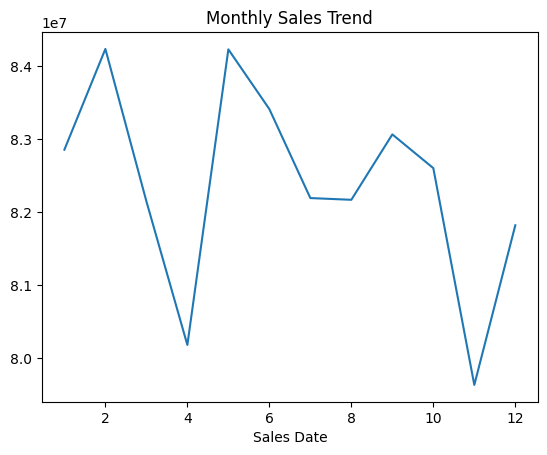

In [ ]:

print("Total Sales:", df['Sales'].sum())
print("Total Profit:", df['Profit'].sum())
print(df.groupby('Region')['Sales'].sum())

df.groupby(pd.to_datetime(df['Sales Date']).dt.month)['Sales'].sum().plot()
plt.title('Monthly Sales Trend')
plt.show()


In [ ]:

df.to_csv('/content/sahil_cleaned.csv', index=False)
print("Cleaned file saved successfully")


Cleaned file saved successfully


In [ ]:

from google.colab import files
files.download('/content/sahil_cleaned.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

cleaned = pd.read_csv('/content/sahil_cleaned.csv')

print("Rows and Columns:", cleaned.shape)
print("Missing Values:", cleaned.isnull().sum().sum())
print("Duplicate Rows:", cleaned.duplicated().sum())


Rows and Columns: (100000, 25)
Missing Values: 60608
Duplicate Rows: 0
